In [2]:
import torch
import numpy as np

In [3]:
import sys, torch, torchvision
print(sys.executable)
print(torch.__version__, torchvision.__version__)

c:\Users\uniab\anaconda3\envs\MLOPS_Vehicle_Prediction\python.exe
2.14.1+cpu 0.29.1+cpu


In [4]:
import torch.nn as nn
import torch.optim as optim
from torchvision.datasets import MNIST 
from torchvision import transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt 

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device", device)

Using device cpu


In [5]:
transform = transforms.ToTensor()

train_data = MNIST(
    root = "data",
    train = True,
    download= True,
    transform = transform
)

In [6]:
test_data = MNIST(
    root = "data",
    train = False,
    download= True,
    transform = transform
)

In [7]:
train_loader = DataLoader(
    train_data,
    batch_size = 64,
    shuffle= True
)

In [8]:
test_loader = DataLoader(
    test_data,
    batch_size = 64,
    shuffle = False
)

Epoch: 1 | Loss: 317.0873
Epoch: 2 | Loss: 130.0016
Epoch: 3 | Loss: 91.1614
Epoch: 4 | Loss: 66.9918
Epoch: 5 | Loss: 54.0137
Total Accuracy: 97.68%
Model saved as mnist_model.pth


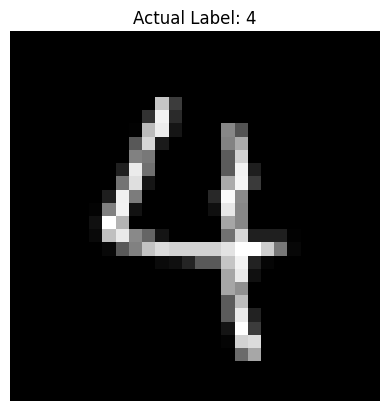

User picked image index: 24
Actual Label: 4
Model Prediction: 4


In [17]:
class DigitModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )


    def forward(self, x):
        return self.net(x)


model = DigitModel().to(device)

loss_fn = nn.CrossEntropyLoss()

optimiser = optim.Adam(model.parameters(), lr = 0.001)

epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for image, labels in train_loader:
        images = image.flatten(start_dim=1).to(device)
        labels = labels.to(device)

        optimiser.zero_grad()

        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimiser.step()

        total_loss+=loss.item()

    print(f"Epoch: {epoch+1} | Loss: {total_loss:.4f}")

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(images.size(0), -1).to(device)   # fixed
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total
print(f"Total Accuracy: {accuracy:.2f}%")

torch.save(model.state_dict(), "mnist_model.pth")
print("Model saved as mnist_model.pth")

index = 24
image, true_label = test_data[index]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual Label: {true_label}")
plt.axis("off")
plt.show()

image_flat = image.view(1, -1).to(device)

with torch.no_grad():
    output = model(image_flat)
    predicted_label = output.argmax(dim=1).item()

print("User picked image index:", index)
print("Actual Label:", true_label)
print("Model Prediction:", predicted_label)

In [6]:
import pyforest
print(lazy_imports())

['from sklearn.model_selection import GridSearchCV', 'import re', 'from sklearn.preprocessing import RobustScaler', 'from pathlib import Path', 'from dask import dataframe as dd', 'import tensorflow as tf', 'from sklearn.decomposition import PCA', 'import pydot', 'from sklearn.linear_model import ElasticNet', 'import statistics', 'from sklearn import metrics', 'import sklearn', 'from sklearn.linear_model import LogisticRegression', 'from sklearn.linear_model import LinearRegression', 'import tqdm', 'from sklearn.model_selection import KFold', 'from xlrd import open_workbook', 'from sklearn.ensemble import RandomForestRegressor', 'import glob', 'from sklearn import svm', 'import pickle', 'from openpyxl import load_workbook', 'import nltk', 'from sklearn.linear_model import ElasticNetCV', 'import spacy', 'from fbprophet import Prophet', 'import imutils', 'import matplotlib.pyplot as plt', 'import plotly.express as px', 'from sklearn.linear_model import Ridge', 'from sklearn.ensemble impo